In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 
sns.set(color_codes=True)

In [2]:
df = pd.read_csv("20260327_Notas_y_Egresados_Enseñanza_Media_2025_PUBL.csv")

In [3]:
df.shape

(290825, 21)

In [4]:
df.head()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,NOM_REG_RBD_A,COD_PRO_RBD,COD_COM_RBD,NOM_COM_RBD,COD_DEPROV_RBD,NOM_DEPROV_RBD,...,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ORIGEN,ENSE_COMPLETA,MARCA_EGRESO
0,2025,2308,6.0,6.0,LGBO,61.0,6115.0,RENGO,61.0,CACHAPOAL,...,4,3.0,2.0,0.0,89,NaN,61.0,SIGE,1,1
1,2025,17810,1.0,8.0,BBIO,82.0,8203.0,CAÑETE,84.0,ARAUCO,...,4,3.0,2.0,0.0,129,NaN,60.0,SIGE,1,1
2,2025,12305,6.0,5.0,VALPO,58.0,5804.0,VILLA ALEMANA,53.0,VALPARAÍSO,...,4,3.0,2.0,0.0,258,NaN,53.0,SIGE,1,1
3,2025,8005,5.0,10.0,LAGOS,102.0,10201.0,CASTRO,102.0,CHILOÉ,...,4,6.0,5.0,0.0,259,NaN,57.0,SIGE,1,1
4,2025,60,4.0,15.0,AYP,151.0,15101.0,ARICA,151.0,ARICA,...,4,3.0,2.0,0.0,326,NaN,63.0,SIGE,1,1


In [5]:
df.describe()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,COD_PRO_RBD,COD_COM_RBD,COD_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
count,290825.0,290825.000000,281940.000000,281939.000000,281939.000000,281939.000000,281939.000000,290825.000000,290825.000000,281939.000000,281939.000000,281939.000000,2.908250e+05,1.507500e+04,282186.000000,290825.0,290825.000000
mean,2025.0,12049.609280,4.457062,9.375209,95.691845,9575.524298,94.020579,376.690250,3.933066,3.246596,2.314089,0.033380,1.396640e+07,2.625776e+07,59.951475,1.0,0.967441
std,0.0,9566.592907,2.879106,4.010426,39.899787,3992.667939,39.258032,102.951697,0.390752,1.342484,1.249776,0.179626,8.171321e+06,1.821352e+06,6.168528,0.0,0.177480
min,2025.0,0.000000,0.000000,1.000000,11.000000,1101.000000,11.000000,310.000000,1.000000,1.000000,1.000000,0.000000,8.900000e+01,1.301430e+05,18.000000,1.0,0.000000
25%,2025.0,4277.000000,2.000000,6.000000,61.000000,6105.000000,61.000000,310.000000,4.000000,3.000000,2.000000,0.000000,6.948563e+06,2.560281e+07,56.000000,1.0,1.000000
50%,2025.0,9877.000000,4.000000,10.000000,101.000000,10101.000000,92.000000,310.000000,4.000000,3.000000,2.000000,0.000000,1.384935e+07,2.614468e+07,61.000000,1.0,1.000000
75%,2025.0,17833.000000,7.000000,13.000000,131.000000,13122.000000,133.000000,410.000000,4.000000,4.000000,3.000000,0.000000,2.080564e+07,2.719090e+07,65.000000,1.0,1.000000
max,2025.0,95850.000000,9.000000,16.000000,163.000000,16305.000000,151.000000,910.000000,4.000000,6.000000,5.000000,1.000000,2.848344e+07,2.848344e+07,70.000000,1.0,1.000000


In [6]:
Columns_Eliminate = ["COD_REG_RBD", "COD_PRO_RBD", "COD_COM_RBD","COD_DEPROV_RBD","COD_DEPE","ORIGEN","DGV_RBD","MRUN_IPE","AGNO"]
df = df.drop(columns=Columns_Eliminate)

In [7]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290825 entries, 0 to 290824
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   RBD             290825 non-null  int64  
 1   NOM_REG_RBD_A   281939 non-null  object 
 2   NOM_COM_RBD     281939 non-null  object 
 3   NOM_DEPROV_RBD  281939 non-null  object 
 4   COD_ENSE        290825 non-null  int64  
 5   COD_GRADO       290825 non-null  int64  
 6   COD_DEPE2       281939 non-null  float64
 7   RURAL_RBD       281939 non-null  float64
 8   MRUN            290825 non-null  int64  
 9   PROM_NOTAS_ALU  282186 non-null  float64
 10  ENSE_COMPLETA   290825 non-null  int64  
 11  MARCA_EGRESO    290825 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 26.6+ MB


In [8]:
Category_columns = { "COD_DEPE2": "category", "RURAL_RBD": "category", "ENSE_COMPLETA": "category", "MARCA_EGRESO": "category", "COD_ENSE": "category","COD_GRADO": "category"}
df = df.astype(Category_columns)

In [9]:
df

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290820,0,NaN,NaN,NaN,310,4,NaN,NaN,28483437,NaN,1,1
290821,0,NaN,NaN,NaN,310,1,NaN,NaN,28483438,NaN,1,0
290822,0,NaN,NaN,NaN,310,2,NaN,NaN,28483438,NaN,1,0
290823,0,NaN,NaN,NaN,310,3,NaN,NaN,28483438,NaN,1,0


In [10]:
df.isnull().sum()

RBD                  0
NOM_REG_RBD_A     8886
NOM_COM_RBD       8886
NOM_DEPROV_RBD    8886
COD_ENSE             0
COD_GRADO            0
COD_DEPE2         8886
RURAL_RBD         8886
MRUN                 0
PROM_NOTAS_ALU    8639
ENSE_COMPLETA        0
MARCA_EGRESO         0
dtype: int64

In [11]:
dfc= df.dropna().copy()

In [12]:
dfc.isnull().sum()

RBD               0
NOM_REG_RBD_A     0
NOM_COM_RBD       0
NOM_DEPROV_RBD    0
COD_ENSE          0
COD_GRADO         0
COD_DEPE2         0
RURAL_RBD         0
MRUN              0
PROM_NOTAS_ALU    0
ENSE_COMPLETA     0
MARCA_EGRESO      0
dtype: int64

In [13]:
dfc

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


In [14]:
dfc = dfc.rename(columns={"RBD": "School ID", "NOM_REG_RBD_A": "Region","NOM_COM_RBD": "Municipality",  "NOM_DEPROV_RBD": "Provincial Department of Education ", "COD_ENSE": "Education level ", "COD_GRADO": "Grade level ","COD_DEPE2": "School dependency","RURAL_RBD": "School rurality","MRUN": "Student ID","PROM_NOTAS_ALU": "GPA","ENSE_COMPLETA": "Complete high school","MARCA_EGRESO": "Graduation status indicator"})

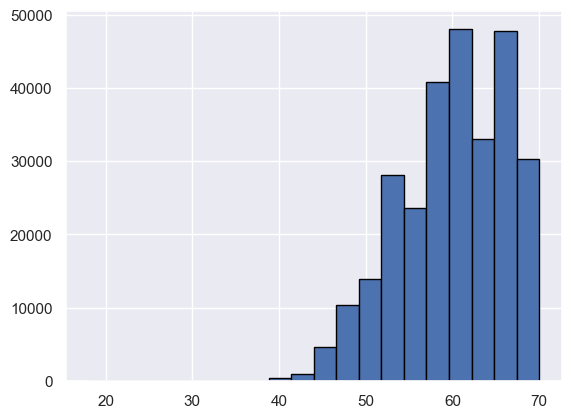

In [15]:
dfc['GPA'].hist(bins=20, edgecolor='black')
plt.show()

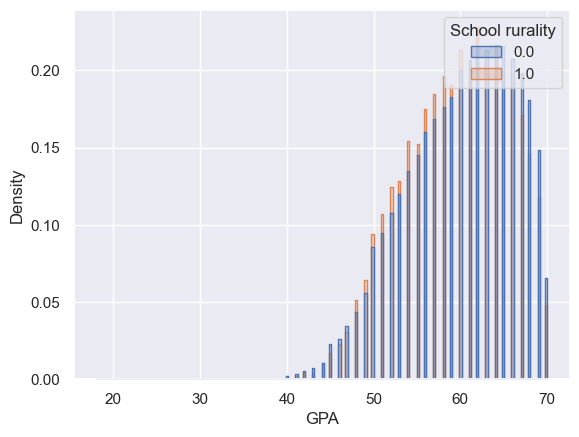

In [16]:
sns.histplot(data=dfc, x='GPA', hue="School rurality",stat="density",common_norm=False,element="step")
plt.show()

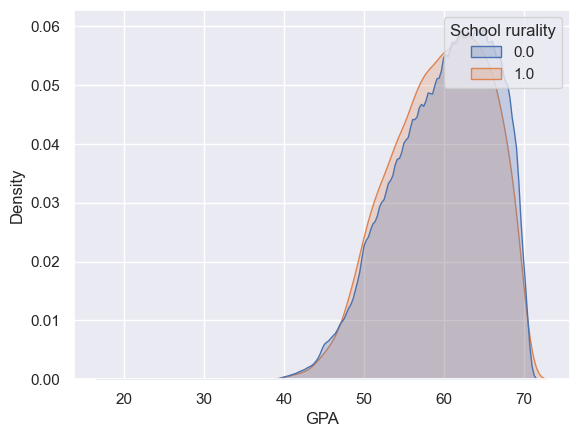

In [34]:
sns.kdeplot(data=dfc, x='GPA', hue="School rurality",common_norm=False, fill=True)
plt.show()

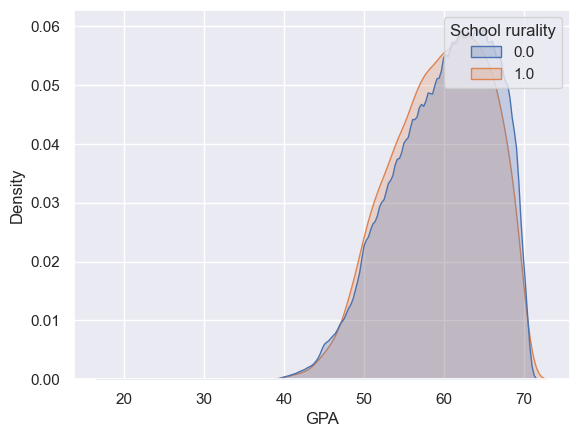

In [34]:
sns.kdeplot(data=dfc, x='GPA', hue="School rurality",common_norm=False, fill=True)
plt.show()

In [17]:
dfc

,School ID,Region,Municipality,Provincial Department of Education,Education level,Grade level,School dependency,School rurality,Student ID,GPA,Complete high school,Graduation status indicator
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


In [18]:
Public = [1, 4, 5]
Private=[3]
conditions = [dfc['School dependency'].isin(Public), dfc['School dependency'].isin(Private)]
results = ['Public', 'Private']
dfc['School_dependency_Public_Private'] = np.select(conditions, results, default="State-funded private school")

In [19]:
dfc['GPA'] = dfc['GPA'].astype('float64')

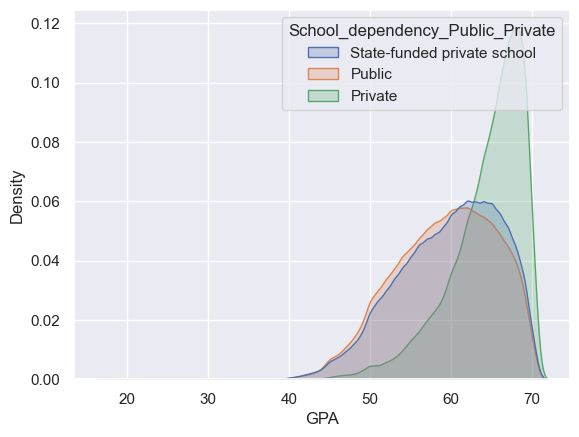

In [20]:
sns.kdeplot(data=dfc, x='GPA', hue='School_dependency_Public_Private',common_norm=False, fill=True)
plt.show()

In [30]:
Gpa = dfc.groupby('Region')['GPA'].agg(Promedio='mean',Desviacion_Estandar='std', Mediana='median',Moda=lambda x: x.mode()[0]).round(2).reset_index()
display(Gpa)

,Region,Promedio,Desviacion_Estandar,Mediana,Moda
0,ANTOF,59.94,5.87,61.0,60.0
1,ARAUC,59.33,6.05,60.0,61.0
2,ATCMA,58.79,6.61,59.0,60.0
3,AYP,60.64,6.15,62.0,66.0
4,AYSEN,59.48,6.14,60.0,65.0
5,BBIO,60.30,6.08,61.0,65.0
6,COQ,59.85,6.05,61.0,63.0
7,LAGOS,59.31,5.96,60.0,62.0
8,LGBO,59.49,6.47,60.0,62.0
9,MAG,60.86,5.71,62.0,62.0
